In [1]:
import pandas as pd

df = pd.read_csv("dataset.csv")

df.head()

,Name,Timestamp,X,Y
0,qdugzqd,"Jan 26, 2026, 12:00:03 AM",54.019410,69.212326
1,qdugzqd,"Jan 26, 2026, 12:00:03 AM",176.670391,66.628831
2,qdugzqd,"Jan 26, 2026, 12:00:03 AM",185.917840,105.632155
3,qdugzqd,"Jan 26, 2026, 12:00:03 AM",127.891247,52.613789
4,qdugzqd,"Jan 26, 2026, 12:00:03 AM",89.019781,36.288286


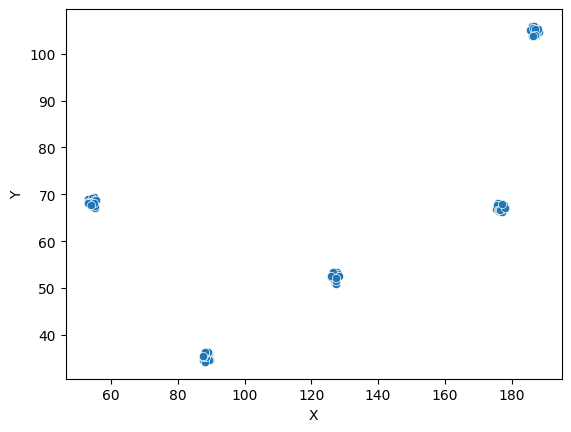

In [2]:
#subtaskuri and a bit of EDA
subtask1 = df.Timestamp.nunique()

import matplotlib.pyplot as plt
import seaborn as sns

subtask2 = 5 # se vad 5 clusteruri (am micsorat numaru de sample uri sa se vada bine)

sns.scatterplot(x=df.X[100:200], y=df.Y[100:200])
plt.show()

In [3]:
df_1 = pd.DataFrame({
    "id": "GLOBAL",
    "subtaskID": ["task1", "task2"],
    "answer": [subtask1, subtask2]
})

df_1

,id,subtaskID,answer
0,GLOBAL,task1,50
1,GLOBAL,task2,5


[[ 54.62844385  68.35512374]
 [176.66201506  67.23041177]
 [ 88.7628524   35.30249776]
 [127.11129975  52.15543685]
 [186.82262315 104.63050812]]


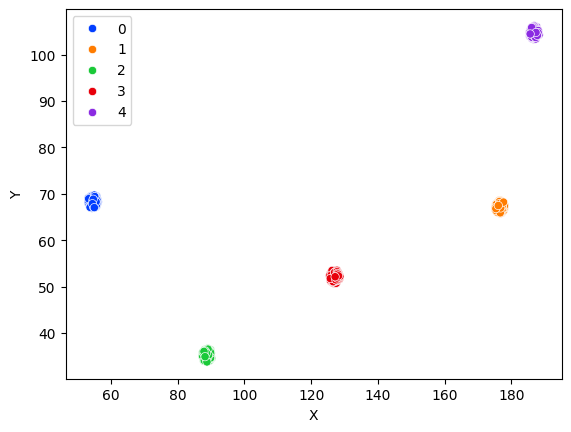

In [12]:
from sklearn.cluster import KMeans # asta e principiul gen pt fiecare timestamp
time = df.Timestamp[0]
sparks = df[df.Timestamp == time][['X', 'Y']]

model = KMeans(n_clusters=5)
labels = model.fit_predict(sparks)

print(model.cluster_centers_)

sns.scatterplot(x=sparks.X, y=sparks.Y, hue=labels, palette='bright')
plt.show()

In [13]:
from sklearn.cluster import KMeans

ids = []
answers = []

times = df.Timestamp.unique()
for time in times:
    sparks = df[df.Timestamp == time][['X', 'Y']]

    model = KMeans(n_clusters=5)
    labels = model.fit_predict(sparks)
    centers = model.cluster_centers_
    
    for i in range(5):
        idx = f"{time}|{i}"
        ids.append(idx)
        answer = f'{centers[i][0]}|{centers[i][1]}'
        answers.append(answer)

In [18]:
df_2 = pd.DataFrame({
    "id": ids,
    "subtaskID": "task3",
    "answer": answers
})

df_2.head()

,id,subtaskID,answer
0,"Jan 26, 2026, 12:00:03 AM|0",task3,176.6620150587668|67.23041177368826
1,"Jan 26, 2026, 12:00:03 AM|1",task3,88.76285239985327|35.30249775743958
2,"Jan 26, 2026, 12:00:03 AM|2",task3,54.62844385058159|68.35512373510925
3,"Jan 26, 2026, 12:00:03 AM|3",task3,127.11129974788031|52.155436847756576
4,"Jan 26, 2026, 12:00:03 AM|4",task3,186.82262314832118|104.63050811654105


In [19]:
submission = pd.concat([df_1, df_2])
submission.to_csv("submission.csv", index=False)

In [20]:
submission

,id,subtaskID,answer
0,GLOBAL,task1,50
1,GLOBAL,task2,5
0,"Jan 26, 2026, 12:00:03 AM|0",task3,176.6620150587668|67.23041177368826
1,"Jan 26, 2026, 12:00:03 AM|1",task3,88.76285239985327|35.30249775743958
2,"Jan 26, 2026, 12:00:03 AM|2",task3,54.62844385058159|68.35512373510925
...,...,...,...
245,"Jan 26, 2026, 12:05:47 AM|0",task3,106.99863883985036|146.48347163182387
246,"Jan 26, 2026, 12:05:47 AM|1",task3,240.08722569025653|181.49375102646565
247,"Jan 26, 2026, 12:05:47 AM|2",task3,145.33345897296465|110.81634641529104
248,"Jan 26, 2026, 12:05:47 AM|3",task3,183.37057269334468|130.17387898033775
